## 0. Persiapan: import library dan ekstraksi data

In [1]:
# !pip install opencv-python numpy matplotlib scikit-image pandas

import zipfile
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 110
print("OpenCV:", cv2.__version__)

OpenCV: 5.0.0


In [6]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DI_COLAB = True
except ImportError:
    DI_COLAB = False

DRIVE_DIR = Path("/content/drive/MyDrive/Semester 7/PCD") if DI_COLAB else Path(".")

FOLDER_PROYEK = DRIVE_DIR

LOKAL_DIR = Path("/content/data") if DI_COLAB else Path("data")   # tempat ekstraksi zip
OUT_DIR   = FOLDER_PROYEK / "hasil_prapemrosesan"                  # hasil disimpan ke Drive
print("Di Colab:", DI_COLAB, "| Folder proyek:", FOLDER_PROYEK)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Di Colab: True | Folder proyek: /content/drive/MyDrive/Semester 7/PCD


In [7]:
NAMA_SUMBER = {"hvs": "Kertas_HVS", "bergaris": "Kertas_Bergaris"}
EKSTENSI = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

def cari_sumber(nama):
    for kandidat in [FOLDER_PROYEK / f"{nama}.zip", FOLDER_PROYEK / nama]:
        if kandidat.exists():
            return kandidat
    for kandidat in DRIVE_DIR.rglob(f"{nama}*"):
        if kandidat.is_dir() or kandidat.suffix.lower() == ".zip":
            return kandidat
    return None

def siapkan_folder(jenis, sumber):
    if sumber.is_dir():
        return sumber
    tujuan = LOKAL_DIR / jenis
    tujuan.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(sumber) as zf:
        for member in zf.infolist():
            nama = Path(member.filename).name          # abaikan subfolder di dalam zip
            if member.is_dir() or nama.startswith(".") or "__MACOSX" in member.filename:
                continue
            if Path(nama).suffix.lower() in EKSTENSI:
                (tujuan / nama).write_bytes(zf.read(member))
    return tujuan

FOLDER_DATA = {}
for jenis, nama in NAMA_SUMBER.items():
    sumber = cari_sumber(nama)
    if sumber is None:
        print(f"[!] '{nama}' (zip/folder) tidak ditemukan di Drive. Periksa nama atau FOLDER_PROYEK.")
        continue
    FOLDER_DATA[jenis] = siapkan_folder(jenis, sumber)
    jumlah = sum(1 for f in FOLDER_DATA[jenis].rglob("*") if f.suffix.lower() in EKSTENSI)
    print(f"{jenis:9s}: {sumber}  ->  {jumlah} citra")

hvs      : /content/drive/MyDrive/Semester 7/PCD/Kertas_HVS  ->  7 citra
bergaris : /content/drive/MyDrive/Semester 7/PCD/Kertas_Bergaris  ->  7 citra


In [8]:
records = []
for jenis, folder in FOLDER_DATA.items():
    for f in sorted(folder.rglob("*")):
        if f.suffix.lower() not in EKSTENSI or f.name.startswith("."):
            continue
        img = cv2.imread(str(f))                        # OpenCV membaca dalam urutan BGR
        records.append({
            "jenis": jenis,
            "kode": f.stem.split("_")[0],               # contoh: K01_Kamera_HP -> K01
            "file": f.name,
            "path": f,
            "tinggi": img.shape[0],
            "lebar": img.shape[1],
            "citra": img,
        })

df = pd.DataFrame(records)
df[["jenis", "kode", "file", "tinggi", "lebar"]]

,jenis,kode,file,tinggi,lebar
0,hvs,K01,K01_Kamera_HP.jpeg,174,1600
1,hvs,K02,K02_Kamera_HP.jpeg,214,1600
2,hvs,K03,K03_Kamera_HP.jpeg,177,1600
3,hvs,K04,K04_Kamera_HP.jpeg,168,1600
4,hvs,K05,K05_Kamera_HP.jpeg,149,1600
5,hvs,K06,K06_Kamera_HP.jpeg,163,1600
6,hvs,K07,K07_Kamera_HP.jpeg,133,1600
7,bergaris,K01,K01_Kamera_HP.jpeg,251,1599
8,bergaris,K02,K02_Kamera_HP.jpeg,276,1599
9,bergaris,K03,K03_Kamera_HP.jpeg,355,1599


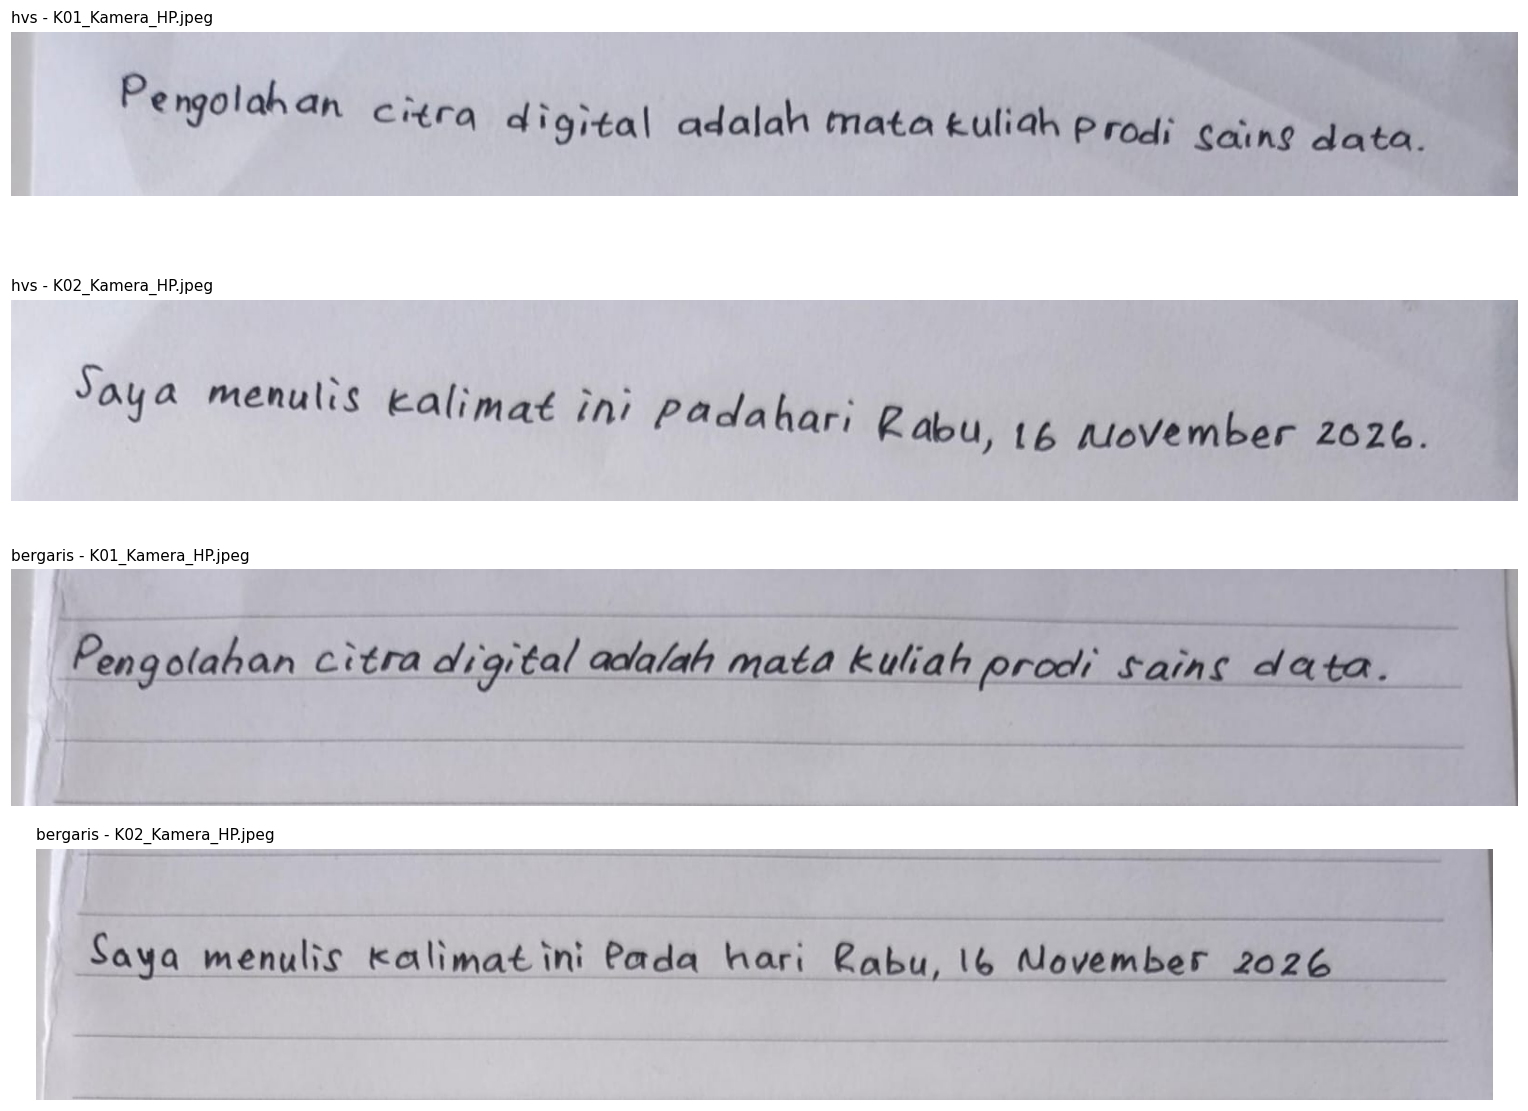

In [9]:
def tampil(citra_list, judul_list, ncols=1, lebar=14, cmap="gray"):
    n = len(citra_list)
    nrows = int(np.ceil(n / ncols))
    tinggi_total = sum(c.shape[0] / c.shape[1] for c in citra_list[::ncols]) * lebar / ncols + 0.6 * nrows
    fig, axes = plt.subplots(nrows, ncols, figsize=(lebar, max(tinggi_total, 2)))
    axes = np.atleast_1d(axes).ravel()
    for ax, c, j in zip(axes, citra_list, judul_list):
        if c.ndim == 3:
            ax.imshow(cv2.cvtColor(c, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(c, cmap=cmap, vmin=0, vmax=255)
        ax.set_title(j, fontsize=10, loc="left")
        ax.axis("off")
    for ax in axes[n:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# Contoh citra asli dari tiap jenis kertas
contoh = df.groupby("jenis").head(2)
tampil(list(contoh["citra"]), [f"{r.jenis} - {r.file}" for r in contoh.itertuples()])

In [10]:
def ke_grayscale(img_bgr):
    return cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

df["gray"] = df["citra"].apply(ke_grayscale)

img = df.loc[0, "citra"].astype(np.float64)
B, G, R = img[..., 0], img[..., 1], img[..., 2]
manual = np.round(0.299 * R + 0.587 * G + 0.114 * B).astype(np.uint8)
print("Selisih maks. rumus manual vs OpenCV:", np.abs(manual.astype(int) - df.loc[0, "gray"].astype(int)).max())

Selisih maks. rumus manual vs OpenCV: 0


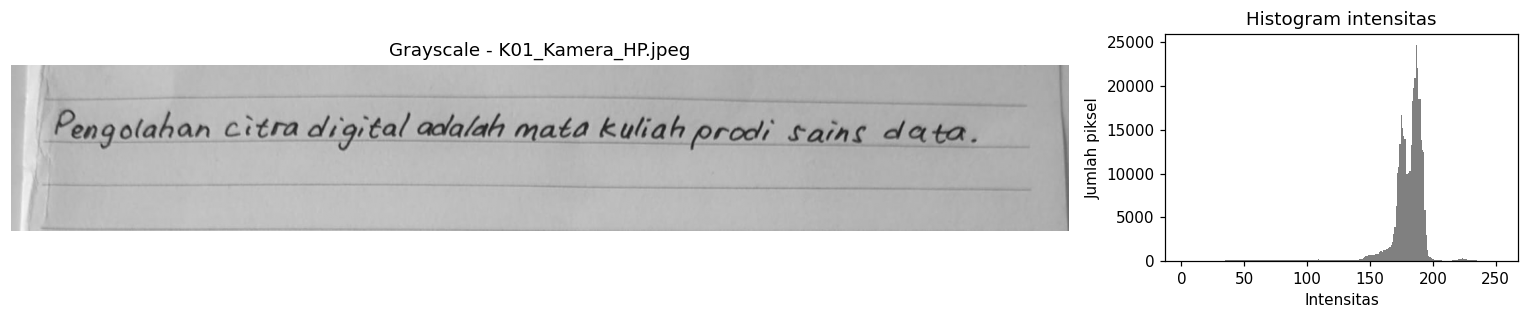

In [11]:
i = df.index[df["jenis"] == "bergaris"][0]
fig, ax = plt.subplots(1, 2, figsize=(14, 3), gridspec_kw={"width_ratios": [3, 1]})
ax[0].imshow(df.loc[i, "gray"], cmap="gray", vmin=0, vmax=255); ax[0].set_title("Grayscale - " + df.loc[i, "file"]); ax[0].axis("off")
ax[1].hist(df.loc[i, "gray"].ravel(), bins=256, range=(0, 255), color="gray")
ax[1].set_title("Histogram intensitas"); ax[1].set_xlabel("Intensitas"); ax[1].set_ylabel("Jumlah piksel")
plt.tight_layout(); plt.show()

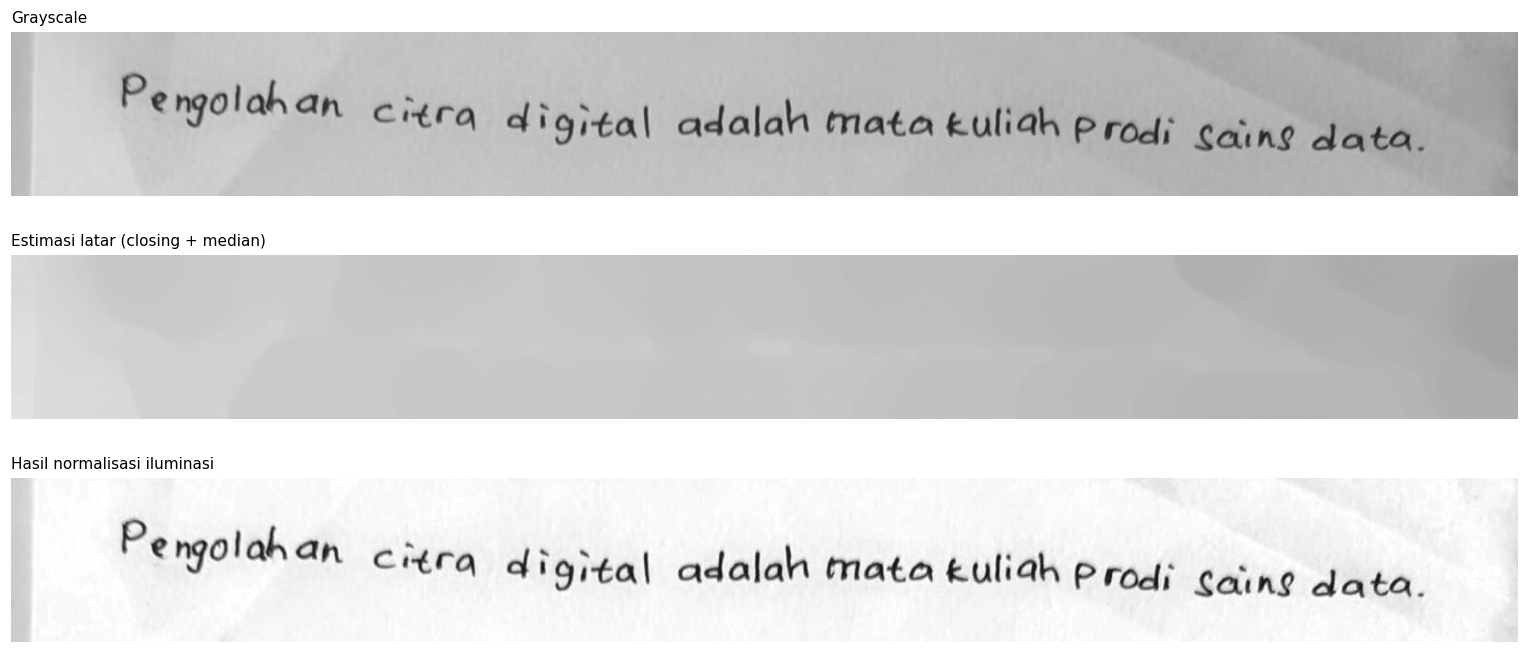

In [12]:
def normalisasi_iluminasi(gray, ukuran_kernel=None):
    # Ukuran kernel jauh lebih besar dari tebal goresan, tetapi lebih kecil dari variasi cahaya
    k = ukuran_kernel or (max(gray.shape) // 20) | 1          # dibuat ganjil
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    latar = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, se)
    latar = cv2.medianBlur(latar, 21)
    norm = cv2.divide(gray, latar, scale=255)
    norm = cv2.normalize(norm, None, 0, 255, cv2.NORM_MINMAX)
    return norm, latar

hasil = df["gray"].apply(normalisasi_iluminasi)
df["latar"] = hasil.str[1]
df["norm"]  = hasil.str[0]

i = df.index[df["jenis"] == "hvs"][0]
tampil([df.loc[i, "gray"], df.loc[i, "latar"], df.loc[i, "norm"]],
       ["Grayscale", "Estimasi latar (closing + median)", "Hasil normalisasi iluminasi"])

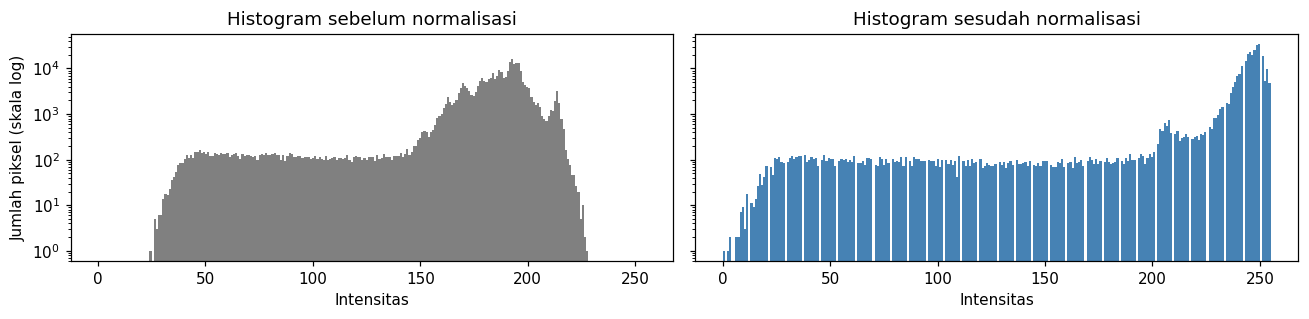

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3), sharey=True)
ax[0].hist(df.loc[i, "gray"].ravel(), bins=256, range=(0, 255), color="gray"); ax[0].set_title("Histogram sebelum normalisasi")
ax[1].hist(df.loc[i, "norm"].ravel(), bins=256, range=(0, 255), color="steelblue"); ax[1].set_title("Histogram sesudah normalisasi")
for a in ax: a.set_xlabel("Intensitas"); a.set_yscale("log")
ax[0].set_ylabel("Jumlah piksel (skala log)")
plt.tight_layout(); plt.show()

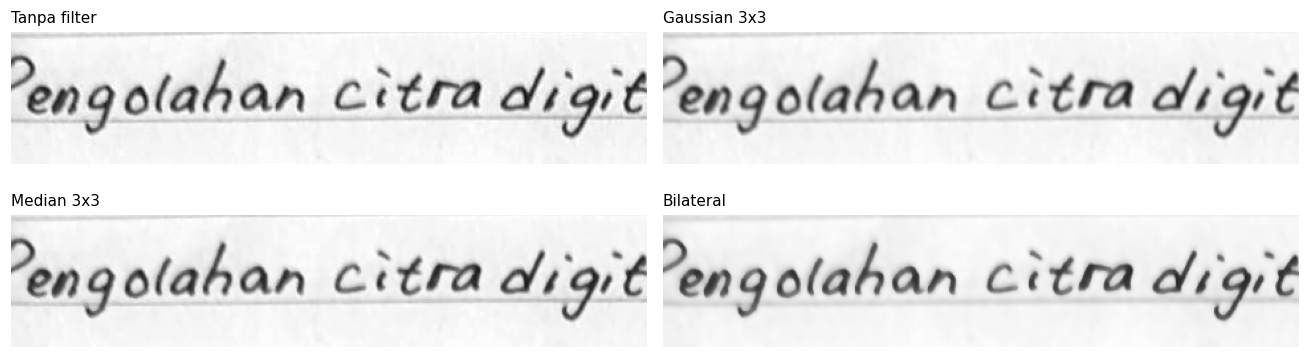

In [14]:
i = df.index[df["jenis"] == "bergaris"][0]
n = df.loc[i, "norm"]
gauss = cv2.GaussianBlur(n, (3, 3), 0)
median = cv2.medianBlur(n, 3)
bilat = cv2.bilateralFilter(n, 7, 50, 50)

# Perbesar satu potongan supaya efek filter terlihat
h, w = n.shape
y0, y1, x0, x1 = int(h * 0.2), int(h * 0.6), int(w * 0.05), int(w * 0.35)
tampil([n[y0:y1, x0:x1], gauss[y0:y1, x0:x1], median[y0:y1, x0:x1], bilat[y0:y1, x0:x1]],
       ["Tanpa filter", "Gaussian 3x3", "Median 3x3", "Bilateral"], ncols=2, lebar=12)

In [15]:
df["denoise"] = df["norm"].apply(lambda x: cv2.medianBlur(x, 3))

## 5. Binarisasi

Empat metode dibandingkan:

| Metode | Keterangan |
|---|---|
| Otsu pada *grayscale* asli | Ambang global; gagal jika pencahayaan tidak rata |
| **Otsu setelah normalisasi** | Ambang global dipilih otomatis dari histogram yang sudah seragam |
| Adaptive Gaussian | Ambang lokal per jendela |
| Sauvola | Ambang lokal berbasis rata-rata dan simpangan baku jendela |

Konvensi yang dipakai: **tinta = 255 (putih), latar = 0 (hitam)**.

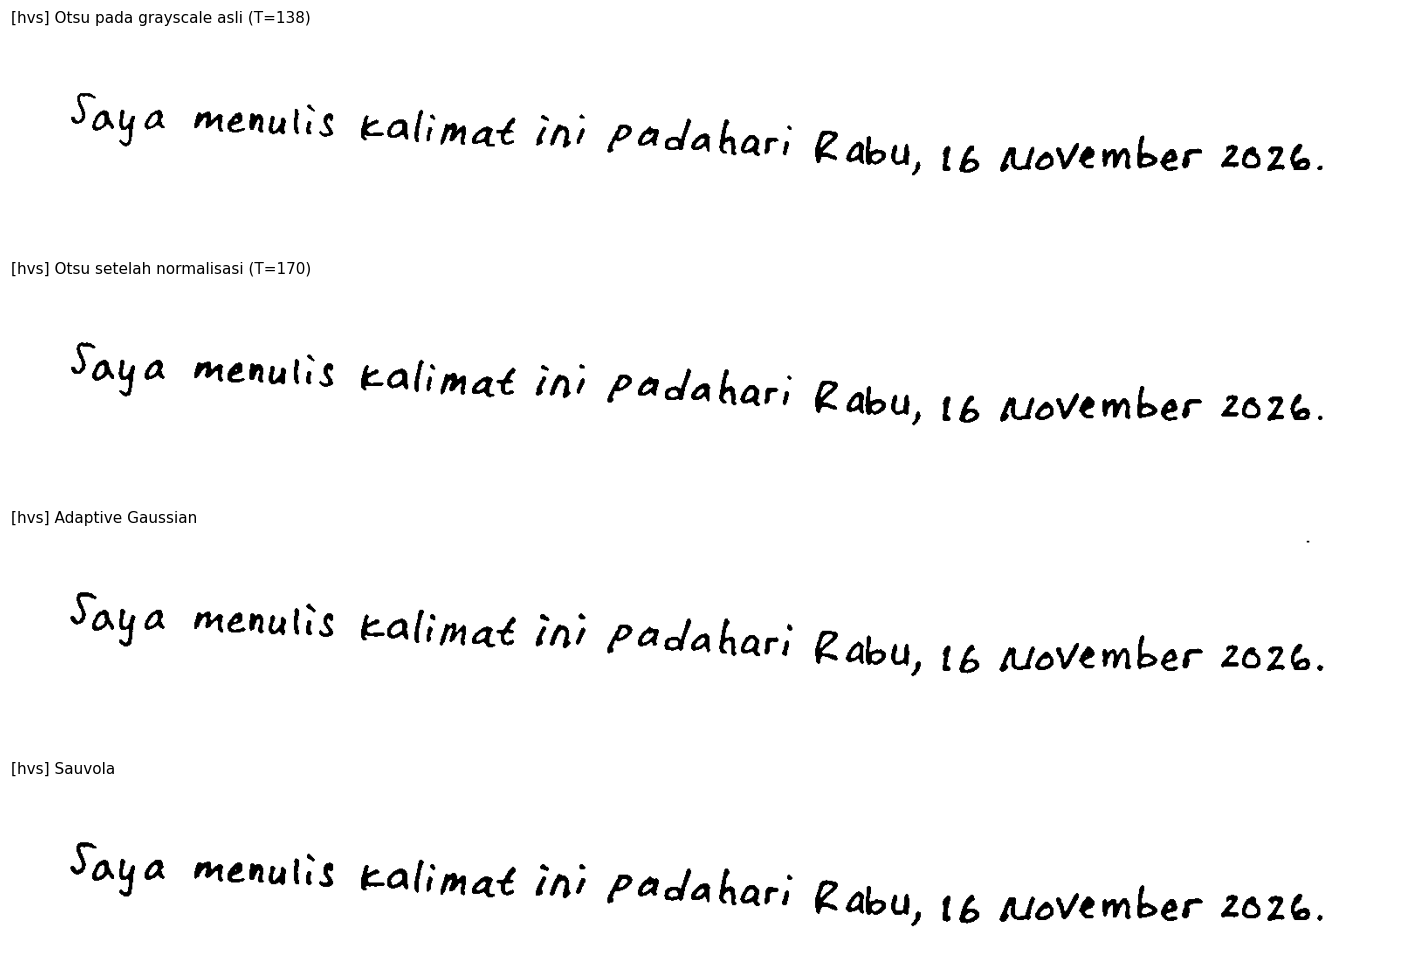

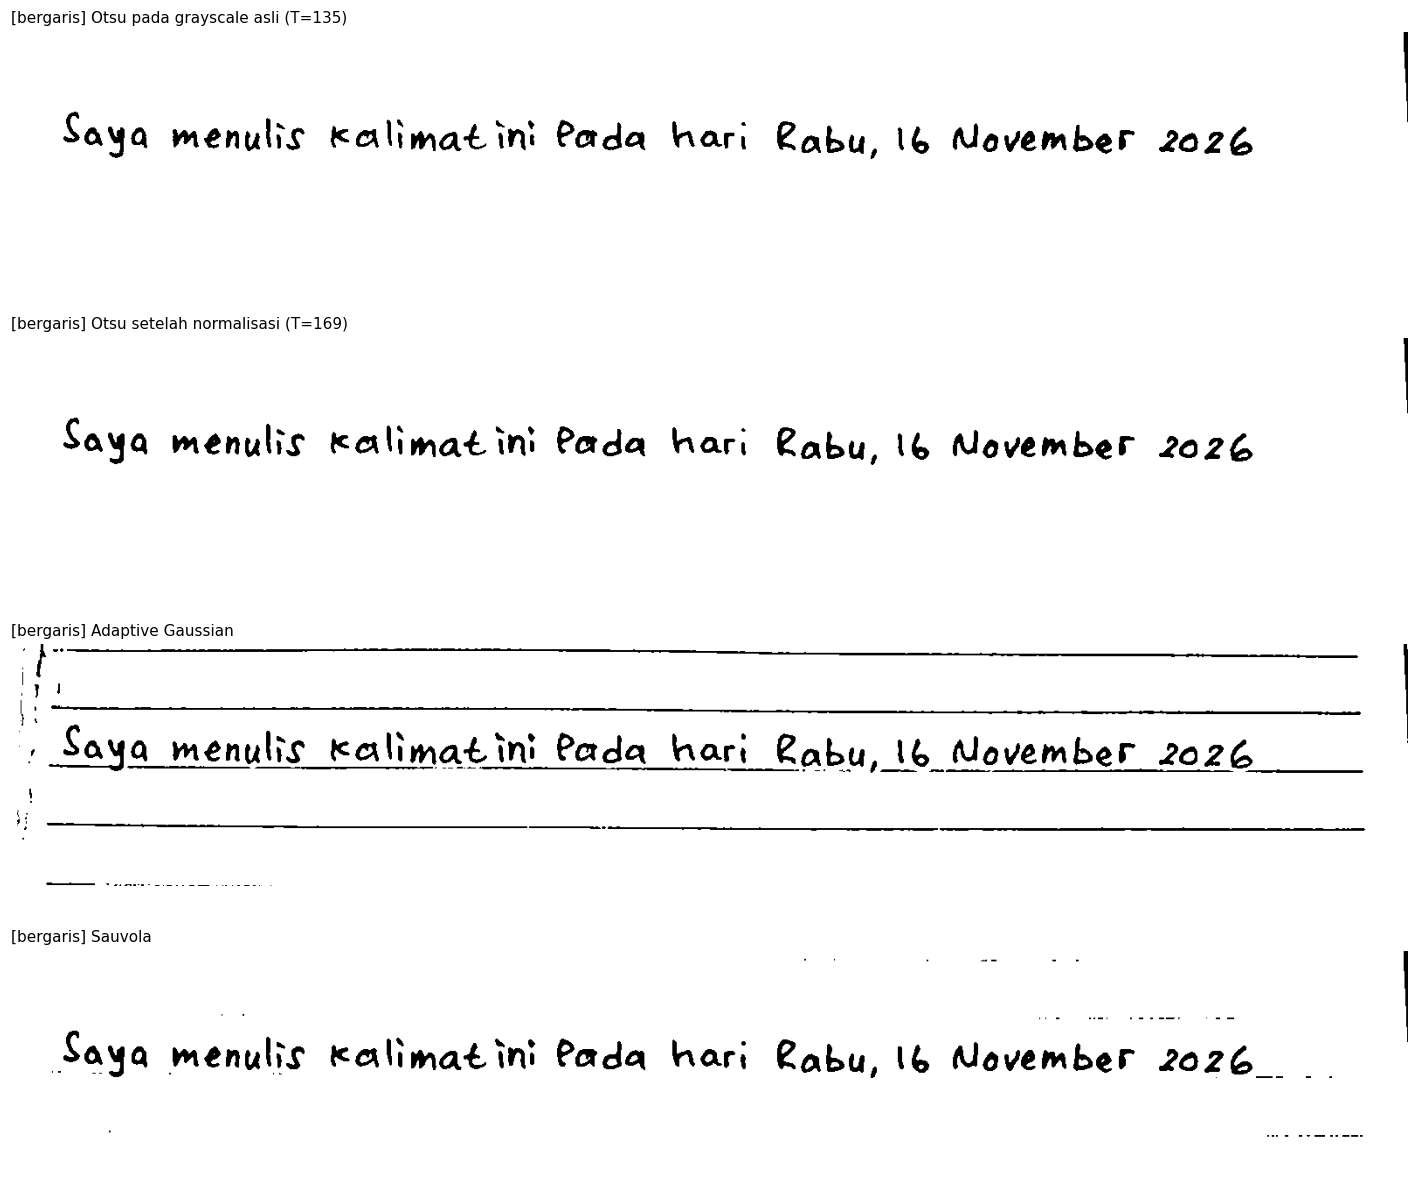

In [16]:
from skimage.filters import threshold_sauvola

def biner_otsu(gray):
    t, b = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return b, t

def biner_adaptive(gray, blok=31, C=15):
    return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                 cv2.THRESH_BINARY_INV, blok, C)

def biner_sauvola(gray, window=31, k=0.2):
    return ((gray < threshold_sauvola(gray, window_size=window, k=k)) * 255).astype(np.uint8)

for jenis in ["hvs", "bergaris"]:
    i = df.index[df["jenis"] == jenis][1]
    g, d = df.loc[i, "gray"], df.loc[i, "denoise"]
    b1, t1 = biner_otsu(g)
    b2, t2 = biner_otsu(d)
    tampil([255 - b1, 255 - b2, 255 - biner_adaptive(d), 255 - biner_sauvola(d)],
           [f"[{jenis}] Otsu pada grayscale asli (T={t1:.0f})",
            f"[{jenis}] Otsu setelah normalisasi (T={t2:.0f})",
            f"[{jenis}] Adaptive Gaussian",
            f"[{jenis}] Sauvola"], lebar=13)

In [17]:
hasil = df["denoise"].apply(biner_otsu)
df["biner"]     = hasil.str[0]
df["ambang_otsu"] = hasil.str[1]
df[["jenis", "kode", "ambang_otsu"]].T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
jenis,hvs,hvs,hvs,hvs,hvs,hvs,hvs,bergaris,bergaris,bergaris,bergaris,bergaris,bergaris,bergaris
kode,K01,K02,K03,K04,K05,K06,K07,K01,K02,K03,K04,K05,K06,K07
ambang_otsu,168.0,170.0,177.0,173.0,169.0,170.0,170.0,170.0,169.0,170.0,168.0,165.0,165.0,167.0


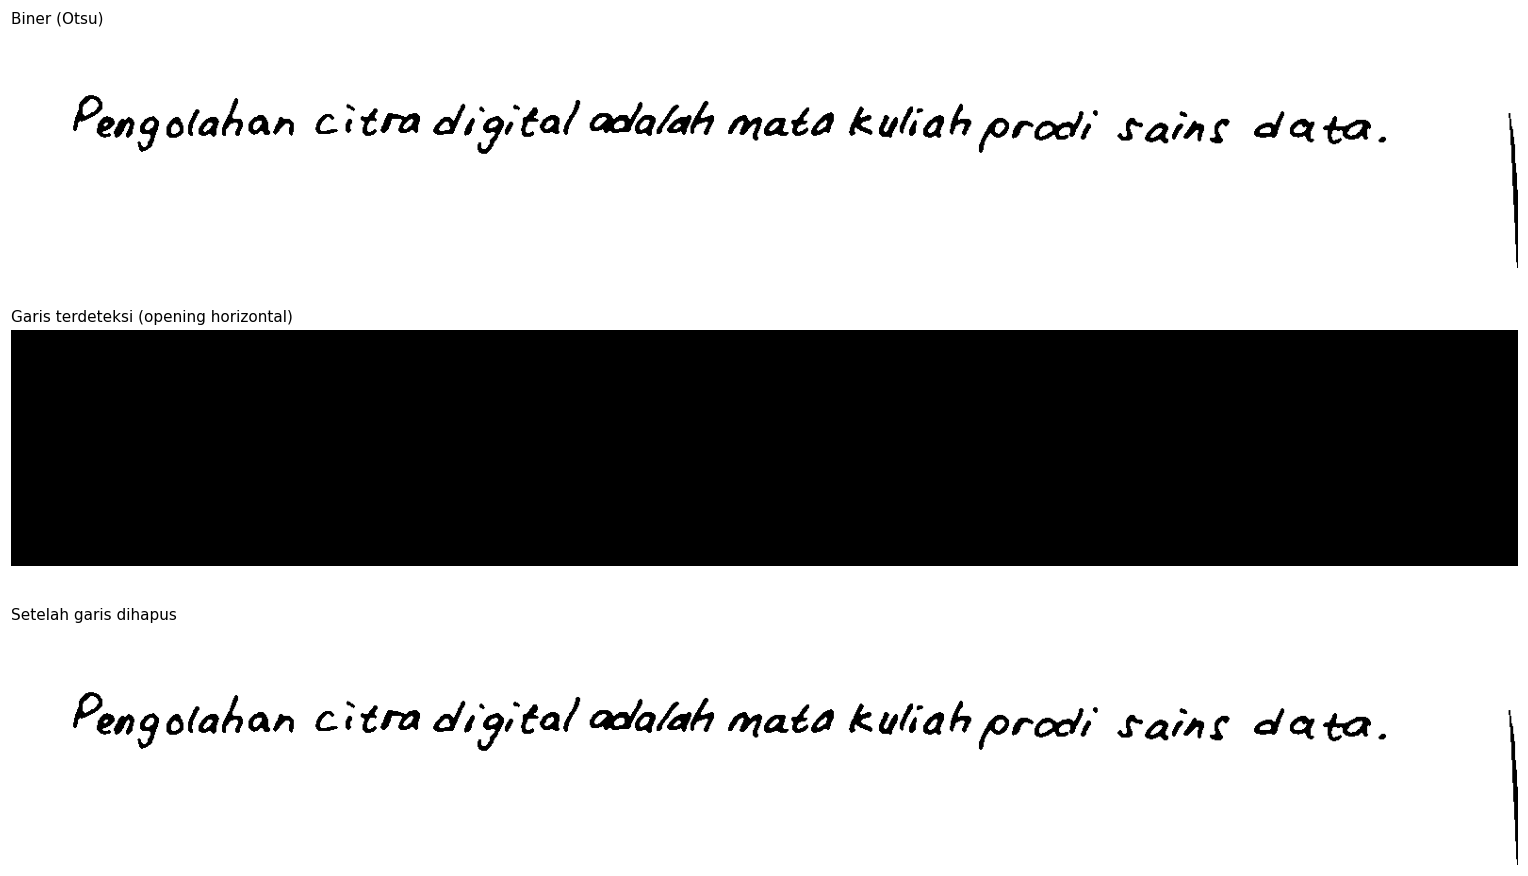

,mean,min,max
jenis,,,
bergaris,0.0,0.0,0.0
hvs,0.0,0.0,0.0


In [18]:
def hapus_garis_horizontal(biner, rasio=15):
    panjang = max(biner.shape[1] // rasio, 20)
    se = cv2.getStructuringElement(cv2.MORPH_RECT, (panjang, 1))
    garis = cv2.morphologyEx(biner, cv2.MORPH_OPEN, se)
    return cv2.subtract(biner, garis), garis

hasil = df["biner"].apply(hapus_garis_horizontal)
df["tanpa_garis"] = hasil.str[0]
df["garis"]       = hasil.str[1]
df["px_garis_dihapus"] = df["garis"].apply(lambda g: int((g > 0).sum()))

i = df.index[df["jenis"] == "bergaris"][0]
tampil([255 - df.loc[i, "biner"], df.loc[i, "garis"], 255 - df.loc[i, "tanpa_garis"]],
       ["Biner (Otsu)", "Garis terdeteksi (opening horizontal)", "Setelah garis dihapus"])
df.groupby("jenis")["px_garis_dihapus"].describe()[["mean", "min", "max"]]

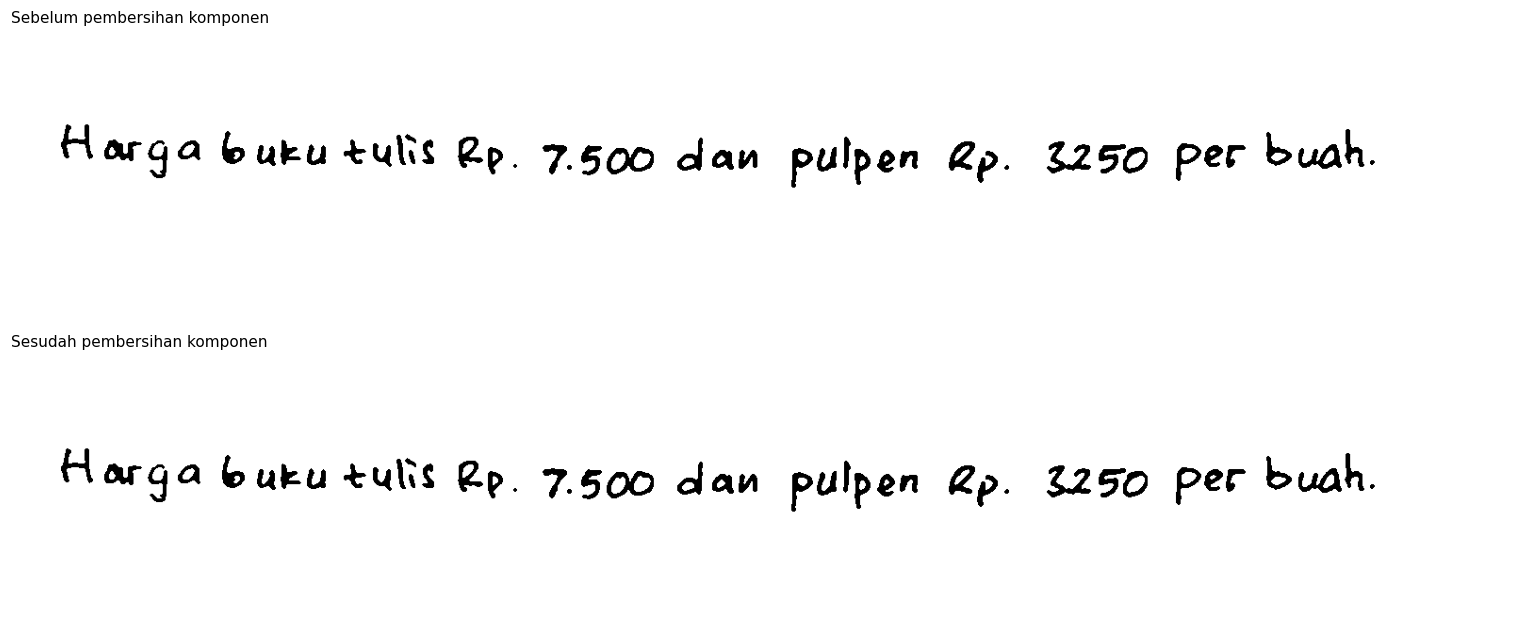

,jenis,kode,buang_kecil,buang_sisa_garis,buang_tepi
0,hvs,K01,0,0,0
1,hvs,K02,0,0,0
2,hvs,K03,0,0,0
3,hvs,K04,0,0,0
4,hvs,K05,0,0,0
5,hvs,K06,0,0,0
6,hvs,K07,0,0,0
7,bergaris,K01,0,0,1
8,bergaris,K02,0,0,1
9,bergaris,K03,0,0,0


In [19]:
def bersihkan_komponen(biner, luas_min=8):
    H, W = biner.shape
    n, label, stats, _ = cv2.connectedComponentsWithStats(biner, connectivity=8)
    simpan = np.zeros(n, dtype=bool)
    alasan = {"kecil": 0, "sisa_garis": 0, "tepi": 0}
    for k in range(1, n):
        x, y, w, h, luas = stats[k]
        menyentuh_tepi = x == 0 or y == 0 or x + w >= W or y + h >= H
        if luas < luas_min:
            alasan["kecil"] += 1; continue
        if h <= 4 and w >= 3 * h and w > 8:
            alasan["sisa_garis"] += 1; continue
        if menyentuh_tepi and (w >= 0.5 * W or h <= 3 or (h >= 0.2 * H and w <= 0.02 * W)):
            alasan["tepi"] += 1; continue
        simpan[k] = True
    return np.where(simpan[label], 255, 0).astype(np.uint8), alasan

hasil = df["tanpa_garis"].apply(bersihkan_komponen)
df["bersih"] = hasil.str[0]
df = pd.concat([df, pd.DataFrame(list(hasil.str[1]), index=df.index).add_prefix("buang_")], axis=1)

i = df.index[df["jenis"] == "bergaris"][3]
tampil([255 - df.loc[i, "tanpa_garis"], 255 - df.loc[i, "bersih"]],
       ["Sebelum pembersihan komponen", "Sesudah pembersihan komponen"])
df[["jenis", "kode", "buang_kecil", "buang_sisa_garis", "buang_tepi"]]

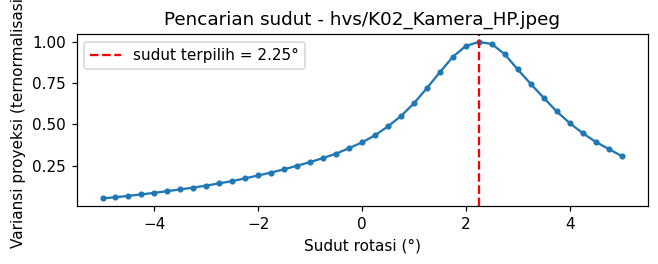

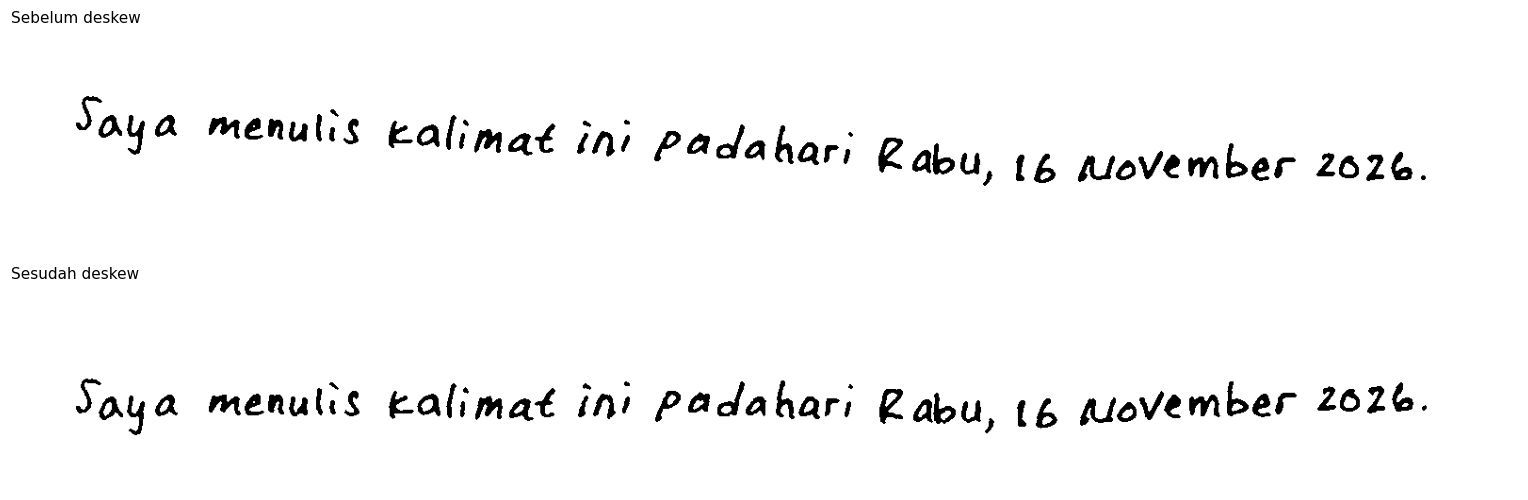

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
jenis,hvs,hvs,hvs,hvs,hvs,hvs,hvs,bergaris,bergaris,bergaris,bergaris,bergaris,bergaris,bergaris
kode,K01,K02,K03,K04,K05,K06,K07,K01,K02,K03,K04,K05,K06,K07
sudut_deskew,1.75,2.25,1.0,0.75,-1.25,1.75,0.0,0.25,0.25,0.0,0.25,0.25,0.0,-0.25


In [20]:
def putar(citra, sudut):
    h, w = citra.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), sudut, 1.0)
    return cv2.warpAffine(citra, M, (w, h), flags=cv2.INTER_NEAREST, borderValue=0)

def estimasi_sudut(biner, rentang=5, langkah=0.25):
    sudut_list = np.arange(-rentang, rentang + 1e-9, langkah)
    skor = [np.var(putar(biner, a).sum(axis=1, dtype=np.float64)) for a in sudut_list]
    return float(sudut_list[int(np.argmax(skor))]), sudut_list, np.array(skor)

hasil = df["bersih"].apply(estimasi_sudut)
df["sudut_deskew"] = hasil.str[0]
df["lurus"] = [putar(b, a) for b, a in zip(df["bersih"], df["sudut_deskew"])]

# Visualisasi untuk citra dengan kemiringan terbesar
i = df["sudut_deskew"].abs().idxmax()
_, sl, sk = hasil[i]
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(sl, sk / sk.max(), marker="o", ms=3)
ax.axvline(df.loc[i, "sudut_deskew"], color="red", ls="--", label=f"sudut terpilih = {df.loc[i, 'sudut_deskew']}°")
ax.set_xlabel("Sudut rotasi (°)"); ax.set_ylabel("Variansi proyeksi (ternormalisasi)")
ax.set_title(f"Pencarian sudut - {df.loc[i, 'jenis']}/{df.loc[i, 'file']}"); ax.legend()
plt.tight_layout(); plt.show()

tampil([255 - df.loc[i, "bersih"], 255 - df.loc[i, "lurus"]], ["Sebelum deskew", "Sesudah deskew"])
df[["jenis", "kode", "sudut_deskew"]].T

In [21]:
def crop_padding(biner, pad=20):
    ys, xs = np.where(biner > 0)
    if len(xs) == 0:
        return 255 - biner
    potong = biner[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    potong = cv2.copyMakeBorder(potong, pad, pad, pad, pad, cv2.BORDER_CONSTANT, value=0)
    return 255 - potong                      # teks hitam, latar putih

df["final"] = df["lurus"].apply(crop_padding)

for r in df.itertuples():
    folder = OUT_DIR / r.jenis
    folder.mkdir(parents=True, exist_ok=True)
    df.loc[r.Index, "path_hasil"] = str(folder / f"{r.kode}.png")
    cv2.imwrite(str(folder / f"{r.kode}.png"), r.final)

print("Tersimpan di:", OUT_DIR.resolve())
df[["jenis", "kode", "path_hasil"]]

Tersimpan di: /content/drive/MyDrive/Semester 7/PCD/hasil_prapemrosesan


,jenis,kode,path_hasil
0,hvs,K01,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
1,hvs,K02,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
2,hvs,K03,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
3,hvs,K04,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
4,hvs,K05,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
5,hvs,K06,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
6,hvs,K07,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
7,bergaris,K01,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
8,bergaris,K02,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...
9,bergaris,K03,/content/drive/MyDrive/Semester 7/PCD/hasil_pr...


=== Kertas HVS ===


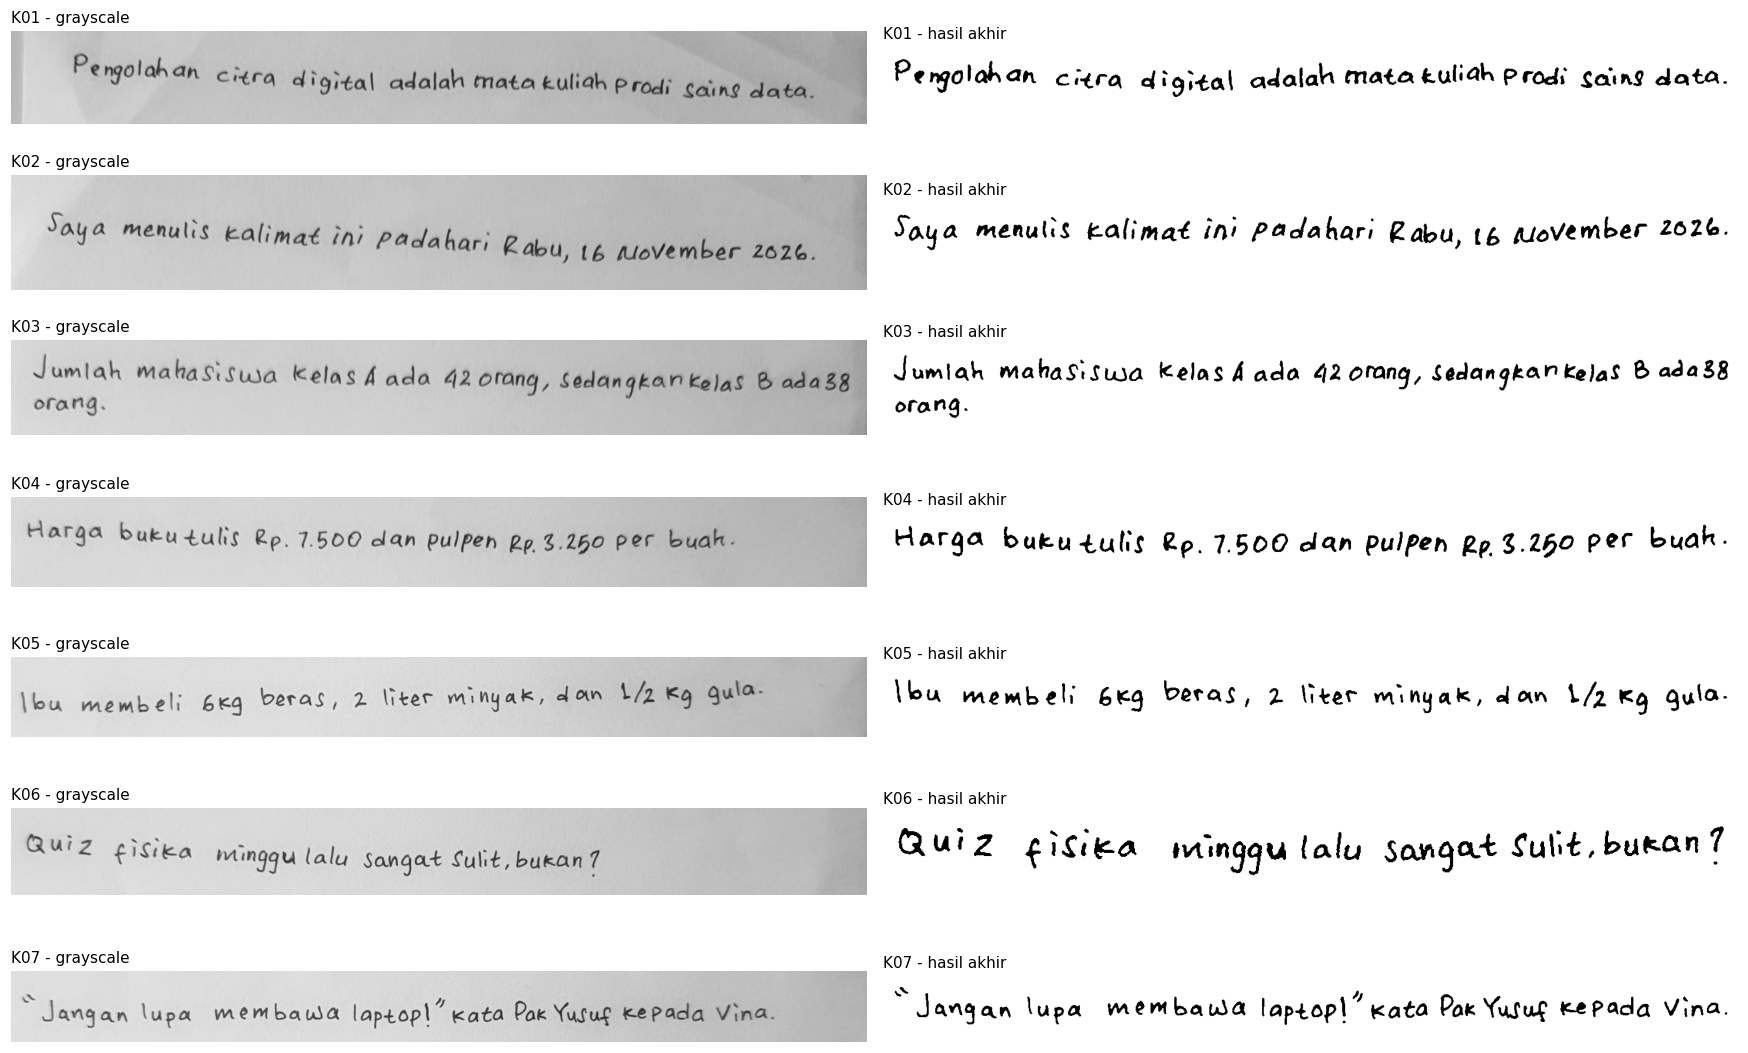

=== Kertas BERGARIS ===


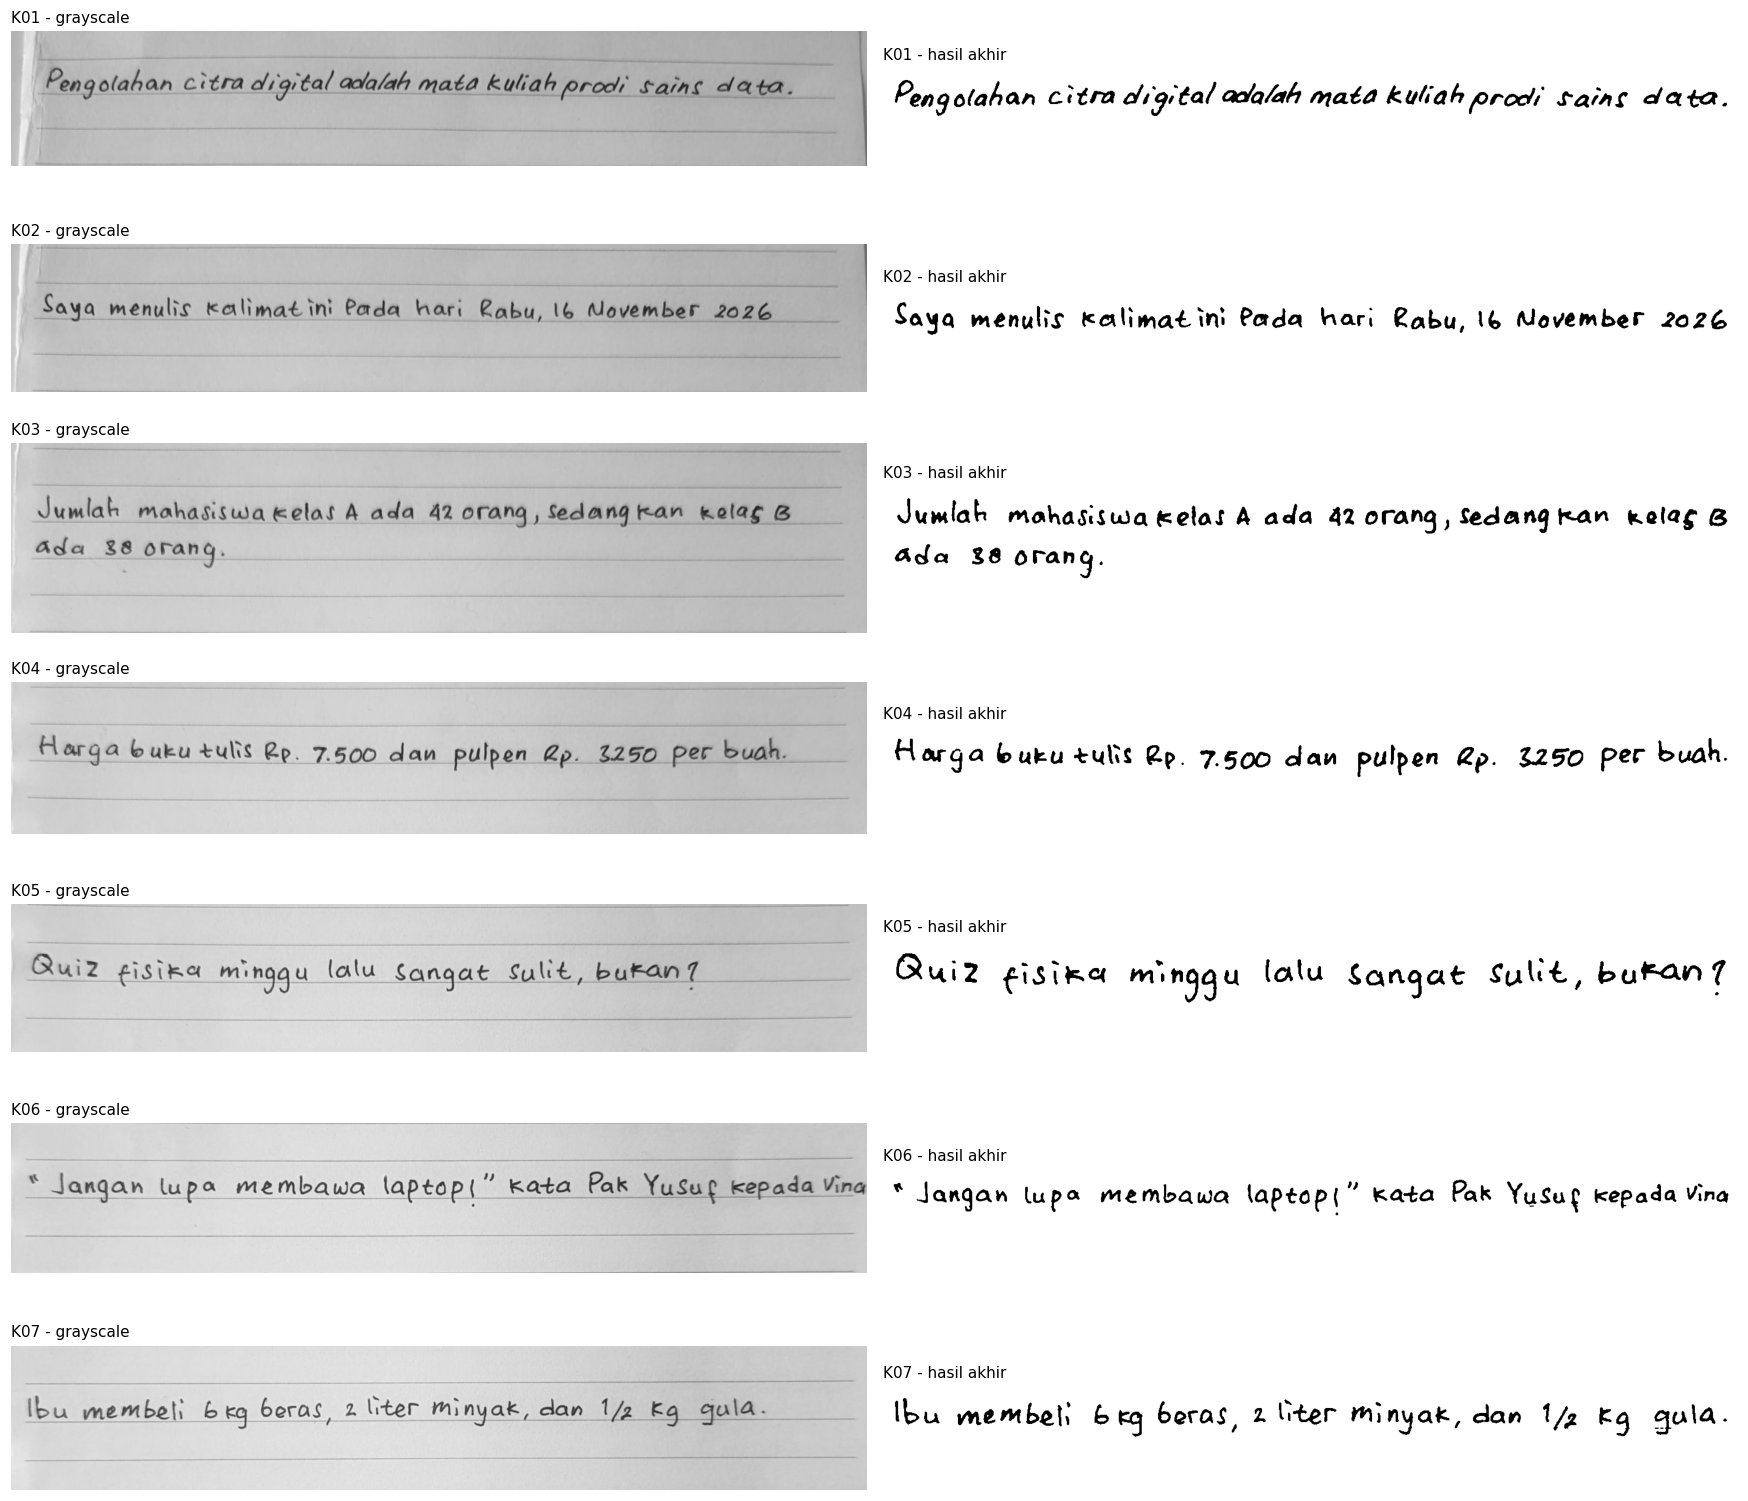

In [22]:
for jenis in ["hvs", "bergaris"]:
    sub = df[df["jenis"] == jenis]
    citra, judul = [], []
    for r in sub.itertuples():
        citra += [r.gray, r.final]
        judul += [f"{r.kode} - grayscale", f"{r.kode} - hasil akhir"]
    print(f"=== Kertas {jenis.upper()} ===")
    tampil(citra, judul, ncols=2, lebar=16)

In [23]:
ringkasan = df[["jenis", "kode", "lebar", "tinggi", "ambang_otsu", "px_garis_dihapus",
                "buang_kecil", "buang_sisa_garis", "buang_tepi", "sudut_deskew"]]
ringkasan.to_csv(OUT_DIR / "ringkasan_prapemrosesan.csv", index=False)
ringkasan

,jenis,kode,lebar,tinggi,ambang_otsu,px_garis_dihapus,buang_kecil,buang_sisa_garis,buang_tepi,sudut_deskew
0,hvs,K01,1600,174,168.0,0,0,0,0,1.75
1,hvs,K02,1600,214,170.0,0,0,0,0,2.25
2,hvs,K03,1600,177,177.0,0,0,0,0,1.00
3,hvs,K04,1600,168,173.0,0,0,0,0,0.75
4,hvs,K05,1600,149,169.0,0,0,0,0,-1.25
5,hvs,K06,1600,163,170.0,0,0,0,0,1.75
6,hvs,K07,1600,133,170.0,0,0,0,0,0.00
7,bergaris,K01,1599,251,170.0,0,0,0,1,0.25
8,bergaris,K02,1599,276,169.0,0,0,0,1,0.25
9,bergaris,K03,1599,355,170.0,0,0,0,0,0.00
